# MLP (R4)

*Ahmed. Uses the clean table and folds from `02_data-analysis`.*

This is our neural network for both tasks: predicting the maths score (regression) and flagging students below Level 2 (classification). We use scikit-learn's `MLPClassifier` and `MLPRegressor` on the 17 predictors and their `_missing` flags, tune the network size and the penalty on PV1, then run all 10 plausible values on the 5 school folds and combine them with Rubin's rules. At the end we compare it with our gradient boosting baseline.

| Reads | Writes |
|---|---|
| `../data/clean/pisa6_clean.parquet` | `outputs/ahmed_mlp_params.json` |
| `../data/clean/columns.json` | `outputs/ahmed_mlp_results.csv` |
| `../data/clean/folds.csv` | `outputs/figures/ahmed_mlp_vs_hgb.png` |
| `../03_baselines/outputs/ahmed_hgb_results.csv` | |

# 1) Setup and data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, recall_score,
                             root_mean_squared_error, mean_absolute_error, r2_score)

DATA = Path("../data")
OUT = Path("outputs")
FIGS = OUT / "figures"
df = pd.read_parquet(DATA / "clean/pisa6_clean.parquet")
roles = json.loads((DATA / "clean/columns.json").read_text(encoding="utf-8"))
folds = pd.read_csv(DATA / "clean/folds.csv")
df["fold"] = df["CNTSCHID"].map(folds.set_index("CNTSCHID")["fold"])
GROUPS = roles["feature_groups"]
FEATURES = [c for cols in GROUPS.values() for c in cols]
INPUTS = FEATURES + [f"{c}_missing" for c in FEATURES]
PVS = range(1, 11)
w = df["SENWT"] / df["SENWT"].mean()
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# no reading or science scores, no plausible values among the inputs
assert not any(c.startswith("PV") or "READ" in c or "SCIE" in c for c in INPUTS)
X = df[INPUTS]
print(X.shape, "| blanks to fill:", int(X.isna().sum().sum()))

(61775, 34) | blanks to fill: 124267


Unlike the trees, the MLP can't take blanks, and it needs inputs on similar scales. So each model is a pipeline: fill blanks with the median, standardise, then the network. The pipeline learns the medians and the scaling from the training folds only. The `_missing` flags go in as extra inputs, since in the EDA a blank answer went with 17 to 45 points lower in maths and the median alone would hide that.

# 1.1) The loop
The same loop as the gradient boosting notebook, with the model swapped. Training uses the normalised `SENWT` weights, and for classification we also multiply by balanced class weights so the 70% below Level 2 doesn't swamp the model. All metrics use `SENWT` on the test rows.

In [2]:
def make_model(task, params):
    if task == "classification":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             MLPClassifier(**params, early_stopping=True, random_state=0))
    mlp = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                        MLPRegressor(**params, early_stopping=True, random_state=0))
    return TransformedTargetRegressor(regressor=mlp, transformer=StandardScaler())


def score(task, y, p, sw):
    if task == "classification":
        return {"roc_auc": roc_auc_score(y, p, sample_weight=sw),
                "pr_auc": average_precision_score(y, p, sample_weight=sw),
                "balanced_acc": balanced_accuracy_score(y, p > 0.5, sample_weight=sw),
                "recall_below": recall_score(y, p > 0.5, pos_label=1, sample_weight=sw),
                "recall_above": recall_score(y, p > 0.5, pos_label=0, sample_weight=sw)}
    return {"rmse": root_mean_squared_error(y, p, sample_weight=sw),
            "mae": mean_absolute_error(y, p, sample_weight=sw),
            "r2": r2_score(y, p, sample_weight=sw)}


def target(task, pv):
    return df[f"BELOW_L2_PV{pv}"] if task == "classification" else df[f"PV{pv}MATH"]


def run(task, params, pvs):
    rows = []
    for pv in pvs:
        y = target(task, pv)
        for k in range(5):
            train, test = df["fold"] != k, df["fold"] == k
            model = make_model(task, params)
            if task == "classification":
                model.fit(X[train], y[train],
                          mlpclassifier__sample_weight=w[train] * compute_sample_weight("balanced", y[train]))
                p = model.predict_proba(X[test])[:, 1]
            else:
                model.fit(X[train], y[train], mlpregressor__sample_weight=w[train])
                p = model.predict(X[test])
            rows.append({"pv": pv, "fold": k, **score(task, y[test], p, w[test])})
    return pd.DataFrame(rows)


def rubin(res):
    per_pv = res.groupby("pv").mean().drop(columns="fold")
    within = res.groupby("pv").var().drop(columns="fold").mean() / 5
    between = per_pv.var()
    return pd.DataFrame({"score": per_pv.mean(), "se": np.sqrt(within + 1.1 * between)})

For regression, `TransformedTargetRegressor` standardises the maths score before training and turns the predictions back into PISA points. Networks train badly on a target in the hundreds, so this matters. `early_stopping=True` holds back 10% of the training rows and stops once the score on them stops improving.

# 2) Tuning on PV1
A small grid: three network sizes (one hidden layer of 32, or two layers of 64-32 and 128-64) and two values of the L2 penalty `alpha`, 6 settings per task. Each is scored on PV1 with the same 5 folds, by ROC-AUC for classification and RMSE for regression.

In [3]:
GRID = [{"hidden_layer_sizes": size, "alpha": alpha}
        for size in [(32,), (64, 32), (128, 64)] for alpha in [0.0001, 0.01]]

tuning = []
for params in GRID:
    clf_res = run("classification", params, [1])
    reg_res = run("regression", params, [1])
    tuning.append({**params, "roc_auc": clf_res["roc_auc"].mean(), "rmse": reg_res["rmse"].mean()})
tuning = pd.DataFrame(tuning)
tuning.round(4)

,hidden_layer_sizes,alpha,roc_auc,rmse
0,"(32,)",0.0001,0.8101,62.5520
1,"(32,)",0.0100,0.8103,62.4892
2,"(64, 32)",0.0001,0.8085,62.4216
3,"(64, 32)",0.0100,0.8104,62.4277
4,"(128, 64)",0.0001,0.8101,62.0374
5,"(128, 64)",0.0100,0.8125,61.9862


In [4]:
best = {"classification": GRID[tuning["roc_auc"].idxmax()],
        "regression": GRID[tuning["rmse"].idxmin()]}
(OUT / "ahmed_mlp_params.json").write_text(json.dumps(best, indent=2), encoding="utf-8")
best

{'classification': {'hidden_layer_sizes': (128, 64), 'alpha': 0.01},
 'regression': {'hidden_layer_sizes': (128, 64), 'alpha': 0.01}}

> **Note:** the six settings are close: ROC-AUC goes from 0.8085 to 0.8125 and RMSE from 61.99 to 62.55 points. The largest network with the stronger penalty (128-64, `alpha` 0.01) wins both tasks. It sits at the edge of the grid, but going from one layer of 32 to 128-64 gains only 0.002 in ROC-AUC and half a point of RMSE, so we didn't push it further. The winners are saved to `outputs/ahmed_mlp_params.json`.

# 3) Classification: below Level 2, all 10 PVs

In [5]:
clf_res = run("classification", best["classification"], PVS)
rubin(clf_res).round(3)

,score,se
roc_auc,0.812,0.004
pr_auc,0.900,0.002
balanced_acc,0.730,0.004
recall_below,0.817,0.012
recall_above,0.642,0.016


> **Note:** over all 10 PVs the ROC-AUC is 0.812 (se 0.004) and the PR-AUC 0.900. At the 0.5 threshold the balanced accuracy is 0.730 (se 0.004), with 81.7% of the students below Level 2 caught and 64.2% of those above it correctly left out (se 0.016).

# 4) Regression: maths score, all 10 PVs

In [6]:
reg_res = run("regression", best["regression"], PVS)
rubin(reg_res).round(3)

,score,se
rmse,61.745,0.307
mae,48.479,0.302
r2,0.410,0.012


> **Note:** the RMSE is 61.75 points (se 0.31), the MAE 48.48 and R² 0.410 (se 0.012).

# 5) Results table
Both tasks in one long table, the same shape as `ahmed_hgb_results.csv`, so the two can be stacked.

In [7]:
results = pd.concat([rubin(clf_res).assign(task="classification"),
                     rubin(reg_res).assign(task="regression")])
results = results.rename_axis("metric").reset_index().assign(model="mlp")
results = results[["model", "task", "metric", "score", "se"]]
results.to_csv(OUT / "ahmed_mlp_results.csv", index=False)
results.round(3)

,model,task,metric,score,se
0,mlp,classification,roc_auc,0.812,0.004
1,mlp,classification,pr_auc,0.900,0.002
2,mlp,classification,balanced_acc,0.730,0.004
3,mlp,classification,recall_below,0.817,0.012
4,mlp,classification,recall_above,0.642,0.016
5,mlp,regression,rmse,61.745,0.307
6,mlp,regression,mae,48.479,0.302
7,mlp,regression,r2,0.410,0.012


> **Note:** among the 0 to 1 metrics the largest se is 0.016 (recall above Level 2), and the RMSE one is 0.31 points. The se already includes the spread across the 10 PVs.

# 6) MLP vs gradient boosting
We read the gradient boosting results from `03_baselines` and put the two side by side. Both used the same folds, the same weights and all 10 PVs, so the numbers are directly comparable. `diff` is MLP minus gradient boosting: for RMSE and MAE lower is better, so a positive `diff` there means the MLP is worse. `se_diff` combines the two standard errors as if they were independent. They share folds and PVs, so this is on the cautious side.

In [8]:
hgb = pd.read_csv(Path("../03_baselines/outputs") / "ahmed_hgb_results.csv")
both = hgb.merge(results, on=["task", "metric"], suffixes=("_hgb", "_mlp"))
both["diff"] = both["score_mlp"] - both["score_hgb"]
both["se_diff"] = np.sqrt(both["se_hgb"] ** 2 + both["se_mlp"] ** 2)
both = both[["task", "metric", "score_hgb", "se_hgb", "score_mlp", "se_mlp", "diff", "se_diff"]]
both.round(3)

,task,metric,score_hgb,se_hgb,score_mlp,se_mlp,diff,se_diff
0,classification,roc_auc,0.819,0.004,0.812,0.004,-0.006,0.006
1,classification,pr_auc,0.903,0.002,0.900,0.002,-0.004,0.003
2,classification,balanced_acc,0.735,0.004,0.730,0.004,-0.005,0.006
3,classification,recall_below,0.823,0.004,0.817,0.012,-0.006,0.013
4,classification,recall_above,0.647,0.009,0.642,0.016,-0.005,0.018
5,regression,rmse,60.750,0.328,61.745,0.307,0.995,0.449
6,regression,mae,47.675,0.276,48.479,0.302,0.804,0.409
7,regression,r2,0.428,0.012,0.410,0.012,-0.019,0.017


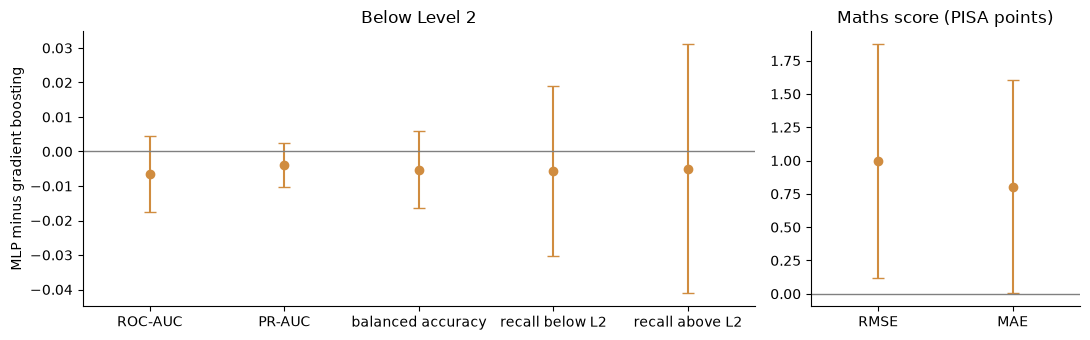

In [9]:
NAMES = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "balanced_acc": "balanced accuracy",
         "recall_below": "recall below L2", "recall_above": "recall above L2", "rmse": "RMSE", "mae": "MAE"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [5, 2]})
for ax, task, title in zip(axes, ["classification", "regression"], ["Below Level 2", "Maths score (PISA points)"]):
    d = both[(both["task"] == task) & (both["metric"] != "r2")]
    x = np.arange(len(d))
    ax.errorbar(x, d["diff"], yerr=1.96 * d["se_diff"], fmt="o", color="#D08C3F", capsize=4)
    ax.axhline(0, color="grey", lw=1)
    ax.set_xticks(x, d["metric"].map(NAMES))
    ax.set_xlim(-0.5, len(d) - 0.5)
    ax.set_title(title)
axes[0].set_ylabel("MLP minus gradient boosting")
fig.tight_layout()
fig.savefig(FIGS / "ahmed_mlp_vs_hgb.png", bbox_inches="tight", dpi=150)
plt.show()

> **Note:** each point is MLP minus gradient boosting for one metric, with a 95% interval (1.96 se_diff). For the 0 to 1 metrics below zero means the MLP scored lower, and for RMSE and MAE above zero means the MLP is worse. R² is left out of the plot because it isn't in PISA points, but it's in the table. The MLP is a little behind on every metric. On the regression errors the gap is about 2 se (RMSE 1.0 point worse with se_diff 0.45, MAE 0.8 with se_diff 0.41), so the MLP is probably slightly worse at predicting the score. The classification gaps are about 1 se or less.

# 7) Summary

- MLP on the 17 predictors and their `_missing` flags (median fill and scaling inside the pipeline), tuned on PV1 with a 6-setting grid, then run on all 10 PVs and 5 school folds. It picked two hidden layers of 128 and 64 with `alpha` 0.01 for both tasks (`outputs/ahmed_mlp_params.json`).
- Pooled, below Level 2: ROC-AUC 0.812 (se 0.004), balanced accuracy 0.730 (se 0.004), recall 0.817 below and 0.642 above Level 2. Maths score: RMSE 61.75 points (se 0.31), R² 0.410 (se 0.012). All in `outputs/ahmed_mlp_results.csv`.
- Against gradient boosting the MLP is slightly behind everywhere. The RMSE and MAE gaps (1.0 and 0.8 points) are each about 2 se, so it's probably a bit worse at predicting the score. The classification gaps (ROC-AUC -0.006) and R² (-0.019) are about 1 se, within the noise. So gradient boosting stays our main model: it's as good or better, and it needs no filling or scaling.

Next: both result tables go into the R4 section of the report, next to the ablations in `../03_baselines/ahmed_ablations.ipynb`.